Author:  
Manuel Eugenio Morocho Cayamcela, PhD

Edited by:
Darío Julián Echeverría Castro

# **Assignment**  
## Outlier handling and group operations for e-commerce transactions

### **Objective and scope of the assignment:**

The objective of this assignment is to apply data mining techniques to identify the most relevant products in our dataset. In addition, the interquartile range (IQR) method will be used to detect and remove outliers, thereby improving the quality of our data and the accuracy of our analyses.

This assignment will cover the following aspects:

1. Loading and initial exploration of the data.
2. Exploratory data analysis to understand the characteristics and distributions of the variables.
3. Applying the IQR method to detect and remove outliers.
4. Applying data mining techniques to identify the most relevant products.
5. Interpreting and visualizing the results.

### **Phase I:** Data Loading and Preprocessing

#### Import the required libraries

In [1]:
#%pip install ______

# Import the 'numpy' library with the alias 'np'
import numpy as np

# Import the 'pandas' library with the alias 'pd'
import pandas as pd

# Import the 'matplotlib.pyplot' library with the alias 'plt'
import matplotlib.pyplot as plt

# Import the 'seaborn' library with the alias 'sns'
import seaborn as sns

# Import the 'datetime' library with the alias 'dt'
import datetime as dt

%matplotlib inline

#### Data loading and preprocessing

In [2]:
# Read the 'ecommerce_transactions.csv' file and load it into a DataFrame named 'transactions'
transactions = pd.read_csv('ecommerce_transactions.csv')

# Display the first 5 rows of the 'transactions' DataFrame using the 'head()' method
transactions.head()

,TransactionNo,Date,ProductNo,ProductName,Price,Quantity,CustomerNo,Country
0,581482,12/9/2019,22485,Set Of 2 Wooden Market Crates,21.47,12,17490.0,United Kingdom
1,581475,12/9/2019,22596,Christmas Star Wish List Chalkboard,10.65,36,13069.0,United Kingdom
2,581475,12/9/2019,23235,Storage Tin Vintage Leaf,11.53,12,13069.0,United Kingdom
3,581475,12/9/2019,23272,Tree T-Light Holder Willie Winkie,10.65,12,13069.0,United Kingdom
4,581475,12/9/2019,23239,Set Of 4 Knick Knack Tins Poppies,11.94,6,13069.0,United Kingdom


In [4]:
# Check the data type of each column with the 'info()' method of the 'transactions' DataFrame
transactions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 536350 entries, 0 to 536349
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   TransactionNo  536350 non-null  object 
 1   Date           536350 non-null  object 
 2   ProductNo      536350 non-null  object 
 3   ProductName    536350 non-null  object 
 4   Price          536350 non-null  float64
 5   Quantity       536350 non-null  int64  
 6   CustomerNo     536295 non-null  float64
 7   Country        536350 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 32.7+ MB


### **Phase II:** Cleaning Outliers

In [5]:
# Check for null values in the 'transactions' DataFrame with the 'isnull().sum()' method
transactions.isna().sum()

TransactionNo     0
Date              0
ProductNo         0
ProductName       0
Price             0
Quantity          0
CustomerNo       55
Country           0
dtype: int64

In [6]:
# Remove null values from the 'transactions' DataFrame with the 'dropna()' method
transactions = transactions.dropna()

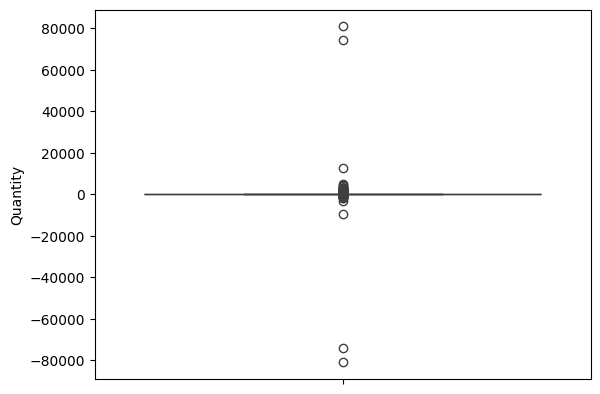

In [7]:
# Use the 'boxplot()' method of the seaborn library 'sns'
# Visualize the distribution of the 'Quantity' variable of the 'transactions' DataFrame
sns.boxplot(y=transactions['Quantity'])
plt.show()

In [9]:
# Calculate the first quartile (Q1) of the 'Quantity' variable of the 'transactions' DataFrame
# Use the 'quantile()' method with the parameter '0.25'
Q1 = transactions['Quantity'].quantile(0.25)

# Calculate the third quartile (Q3) of the 'Quantity' variable of the 'transactions' DataFrame
# Use the 'quantile()' method with the parameter '0.75'
Q3 = transactions['Quantity'].quantile(0.75)

# Calculate the interquartile range (IQR) of the 'Quantity' variable
# by subtracting the first quartile (Q1) from the third quartile (Q3)
IQR = Q3 - Q1
IQR

np.float64(9.0)

In [10]:
# Define the lower bound using the formula Q1 - 1.5 * IQR
# Q1 is the first quartile, IQR is the interquartile range and 1.5 is a scaling factor
lower_bound = Q1 - 1.5 * IQR

# Define the upper bound using the formula Q3 + 1.5 * IQR 
# Q3 is the third quartile, IQR is the interquartile range and 1.5 is a scaling factor
upper_bound = Q3 + 1.5 * IQR

# Filter the outliers of the 'Quantity' variable of the 'transactions' DataFrame 
# Outliers are the observations that fall below the lower bound or above the upper bound
# Use the logical operator '|' to express 'or' in the condition
outliers = (transactions['Quantity'] < lower_bound) | (transactions['Quantity'] > upper_bound)

# Remove the outliers of the 'Quantity' variable from the 'transactions' DataFrame
# Use the '~' operator to negate the condition and keep the values that are not outliers
transactions = transactions[~outliers]

<Axes: ylabel='Quantity'>

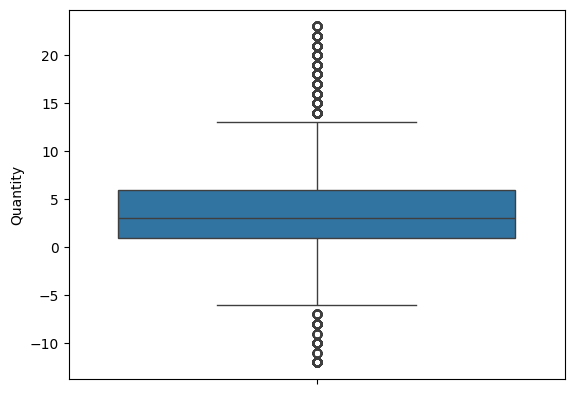

In [11]:
# Check the outliers in the 'Quantity' column again
# Use the 'boxplot()' method of the 'seaborn' library with the 'Quantity' variable
sns.boxplot(y=transactions['Quantity'])

<Axes: ylabel='Quantity'>

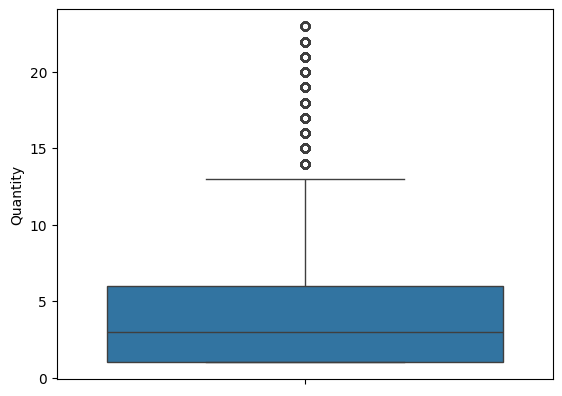

In [12]:
# Remove the negative values from the 'Quantity' column of the 'transactions' DataFrame
# Use the '>' operator to select the values greater than zero (0) in the 'Quantity' column
transactions = transactions[transactions['Quantity'] > 0]

# Check the outliers in the 'Quantity' column again
# Use the 'boxplot()' method of the 'seaborn' library with the 'Quantity' variable on the y-axis
sns.boxplot(y=transactions['Quantity'])

### **Phase III:** Best-selling and highest-revenue products

Create a new column for the revenue per sale

In [13]:
# Use the '*' operator to multiply the 'Price' and 'Quantity' columns of the 'transactions' DataFrame
# Assign the result of the multiplication to the 'Revenue' column of the 'transactions' DataFrame
transactions['Revenue'] = transactions['Price'] * transactions['Quantity']

# Display the first 5 rows of the 'transactions' DataFrame with the 'head()' method
transactions.head()

,TransactionNo,Date,ProductNo,ProductName,Price,Quantity,CustomerNo,Country,Revenue
0,581482,12/9/2019,22485,Set Of 2 Wooden Market Crates,21.47,12,17490.0,United Kingdom,257.64
2,581475,12/9/2019,23235,Storage Tin Vintage Leaf,11.53,12,13069.0,United Kingdom,138.36
3,581475,12/9/2019,23272,Tree T-Light Holder Willie Winkie,10.65,12,13069.0,United Kingdom,127.80
4,581475,12/9/2019,23239,Set Of 4 Knick Knack Tins Poppies,11.94,6,13069.0,United Kingdom,71.64
6,581475,12/9/2019,22118,Joy Wooden Block Letters,11.53,18,13069.0,United Kingdom,207.54


Review the 10 best-selling products

In [14]:
# Group the 'transactions' DataFrame by the 'ProductName' column
# Use the 'groupby()' method and pass the 'ProductName' column as an argument
grouped_products = transactions.groupby('ProductName')

# Sum the 'Quantity' column of each group
# Use the 'sum()' method to add up the 'Quantity' column of each group
total_quantity_by_product = grouped_products['Quantity'].sum()

# Sort the results in descending order
# Use the 'sort_values()' method with the argument 'ascending=False'
# Store the result in the variable 'best_selling_products'
best_selling_products = total_quantity_by_product.sort_values(ascending=False)

# Display the 10 best-selling products with the 'head()' method
best_selling_products.head(10)

ProductName
Jumbo Bag Red Retrospot               14050
Assorted Colour Bird Ornament         11062
Cream Hanging Heart T-Light Holder    10960
Lunch Bag Red Retrospot               10541
Jumbo Bag Vintage Doily                9306
Lunch Bag Vintage Doily                8405
Regency Cakestand 3 Tier               8328
Lunch Bag Suki Design                  8268
Lunch Bag Black Skull                  8218
Lunch Bag Cars Blue                    7928
Name: Quantity, dtype: int64

Visualize the 10 best-selling products

In [23]:
best_selling_products.info()

<class 'pandas.core.series.Series'>
Index: 3701 entries, Jumbo Bag Red Retrospot to Keep Out Girls Door Hanger
Series name: Quantity
Non-Null Count  Dtype
--------------  -----
3701 non-null   int64
dtypes: int64(1)
memory usage: 186.9+ KB


C:\Users\darth\AppData\Local\Temp\ipykernel_21228\1779006926.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=best_selling_products.head(10).values,


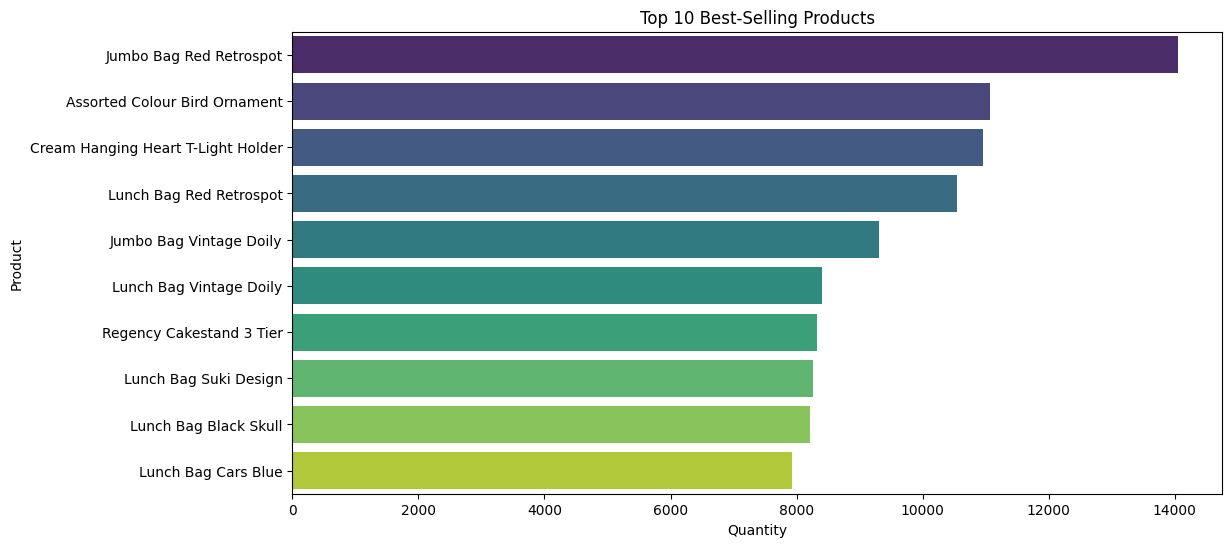

In [24]:
# Create a figure with the 'figure()' method of the matplotlib.pyplot library with the alias 'plt'
# Define the size of the figure with the 'figsize' parameter and the dimensions (12, 6)
plt.figure(figsize=(12, 6))

# Use the 'barplot()' method of the seaborn library 'sns' to show only the 10 best-selling products
# Define the x-axis with the 'Quantity' values of 'best_selling_products'
# Define the y-axis with the index values of 'best_selling_products'
# Define the color palette with the 'palette' parameter and the value 'viridis'
sns.barplot(x=best_selling_products.head(10).values, 
            y=best_selling_products.head(10).index, palette='viridis')

# Define the chart title with the 'title()' method of the matplotlib.pyplot library with the alias 'plt'
# Set the title to 'Top 10 Best-Selling Products'
plt.title('Top 10 Best-Selling Products')

# Define the x-axis label with the 'xlabel()' method of the matplotlib.pyplot library with the alias 'plt'
# Set the x-axis label to 'Quantity'
plt.xlabel('Quantity')

# Define the y-axis label with the 'ylabel()' method of the matplotlib.pyplot library with the alias 'plt'
# Set the y-axis label to 'Product'
plt.ylabel('Product')

# Show the chart with the 'show()' method of the matplotlib.pyplot library with the alias 'plt'
plt.show()

Review the 10 products that have generated the most revenue

In [25]:
# Group the 'transactions' DataFrame by the 'ProductName' column with the 'groupby()' method
grouped_products = transactions.groupby('ProductName')

# Sum the revenue (Revenue) of each product using the 'sum()' method
total_revenue_by_product = grouped_products['Revenue'].sum()

# Sort the results in descending order
# Use the 'sort_values()' method with the argument 'ascending=False'
# Store the result in the variable 'top_revenue_products'
top_revenue_products = total_revenue_by_product.sort_values(ascending=False)

# Display the 10 products that have generated the most revenue with the 'head()' method
top_revenue_products.head(10)

ProductName
Regency Cakestand 3 Tier              188831.32
Cream Hanging Heart T-Light Holder    143410.29
Assorted Colour Bird Ornament         129096.00
Party Bunting                         122645.19
Jumbo Bag Red Retrospot                88625.81
Jam Making Set Printed                 88106.25
Jumbo Shopper Vintage Red Paisley      87483.07
Jumbo Storage Bag Suki                 87134.08
Popcorn Holder                         85207.51
Natural Slate Heart Chalkboard         81275.77
Name: Revenue, dtype: float64

Visualize the products that have generated the most revenue

C:\Users\darth\AppData\Local\Temp\ipykernel_21228\246573569.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_revenue_products.head(10).values,


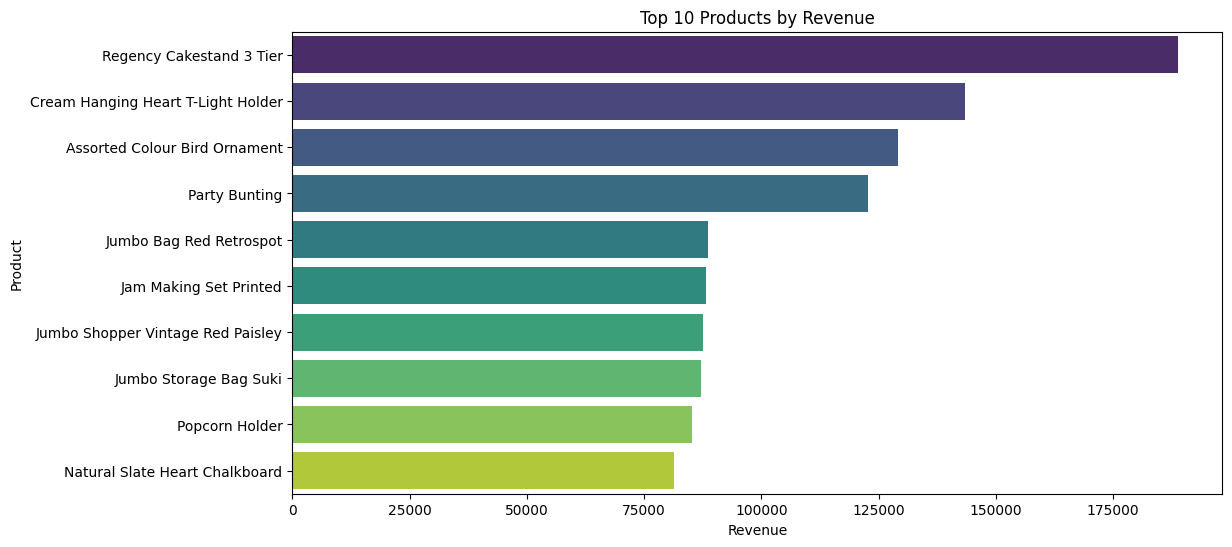

In [26]:
# Create a figure with the 'figure()' method of the matplotlib.pyplot library with the alias 'plt'
# Define the size of the figure with the 'figsize' parameter and the dimensions (12, 6)
plt.figure(figsize=(12, 6))

# Use the 'barplot()' method of the seaborn library 'sns' 
# Visualize only the 10 products that have generated the most revenue 
# Define the x-axis with the 'Revenue' values that correspond to 'top_revenue_products'
# Define the y-axis with the index values of the 10 'top_revenue_products' 
sns.barplot(x=top_revenue_products.head(10).values, 
            y=top_revenue_products.head(10).index, palette='viridis')

# Define the chart title with the 'title()' method of the matplotlib.pyplot library with the alias 'plt'
# Set the title to 'Top 10 Products by Revenue'
plt.title('Top 10 Products by Revenue')

# Define the x-axis label with the 'xlabel()' method of the matplotlib.pyplot library with the alias 'plt'
# Set the x-axis label to 'Revenue'
plt.xlabel('Revenue')

# Define the y-axis label with the 'ylabel()' method of the matplotlib.pyplot library with the alias 'plt'
# Set the y-axis label to 'Product'
plt.ylabel('Product')

# Show the chart with the 'show()' method of the matplotlib.pyplot library with the alias 'plt'
plt.show()

Visualize the distribution of revenue by month

C:\Users\darth\AppData\Local\Temp\ipykernel_21228\4223862453.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sales_by_month.index, y=sales_by_month.values, palette='viridis')


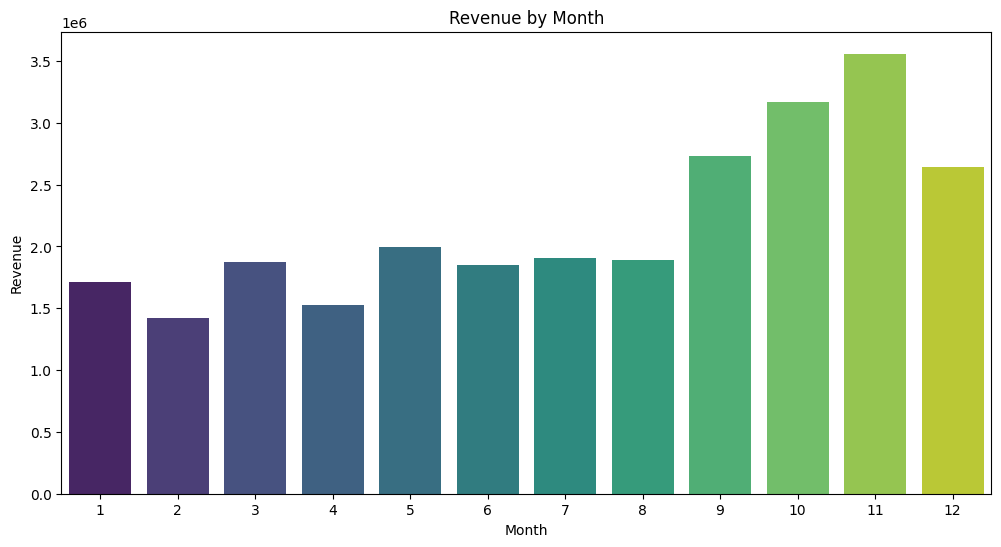

In [27]:
# Convert the 'Date' column of the 'transactions' DataFrame to a date format with the 'to_datetime()' method
# Use the format '%m/%d/%Y' to indicate month, day, and year
# Store the result in the 'Date' column of the 'transactions' DataFrame
transactions['Date'] = pd.to_datetime(transactions['Date'], format  = '%m/%d/%Y')

# Create a new 'Month' column in the 'transactions' DataFrame with the month of each transaction
# Use the 'dt.month' attribute to get the month from the 'Date' column
transactions['Month'] = transactions['Date'].dt.month

# Group the 'transactions' DataFrame by the 'Month' column using the 'groupby()' method
# Sum the revenue (Revenue) per month using the 'sum()' method
# Store the results in the variable 'sales_by_month'
sales_by_month = transactions.groupby('Month')['Revenue'].sum()

# Create a figure with the 'figure()' method of the matplotlib.pyplot library with the alias 'plt'
# Define the size of the figure with the 'figsize' parameter and the dimensions (12, 6)
plt.figure(figsize=(12, 6))

# Use the 'barplot()' method of the seaborn library 'sns' to visualize the data as bars
# Define the x-axis with the index values of 'sales_by_month'
# Define the y-axis with the values of 'sales_by_month'
# Define the color palette with the 'palette' parameter and the value 'viridis'
sns.barplot(x=sales_by_month.index, y=sales_by_month.values, palette='viridis')

# Define the chart title with the 'title()' method of the matplotlib.pyplot library with the alias 'plt'
# Set the title to 'Revenue by Month'
plt.title('Revenue by Month')

# Define the x-axis label with the 'xlabel()' method of the matplotlib.pyplot library with the alias 'plt'
# Set the x-axis label to 'Month'
plt.xlabel('Month')

# Define the y-axis label with the 'ylabel()' method of the matplotlib.pyplot library with the alias 'plt'
# Set the y-axis label to 'Revenue'
plt.ylabel('Revenue')

# Show the chart with the 'show()' method of the matplotlib.pyplot library with the alias 'plt'
plt.show()

Visualize the distribution of sales by day of the week with a bar chart

C:\Users\darth\AppData\Local\Temp\ipykernel_21228\4075666984.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sales_by_weekday.index, y=sales_by_weekday.values, palette='viridis')


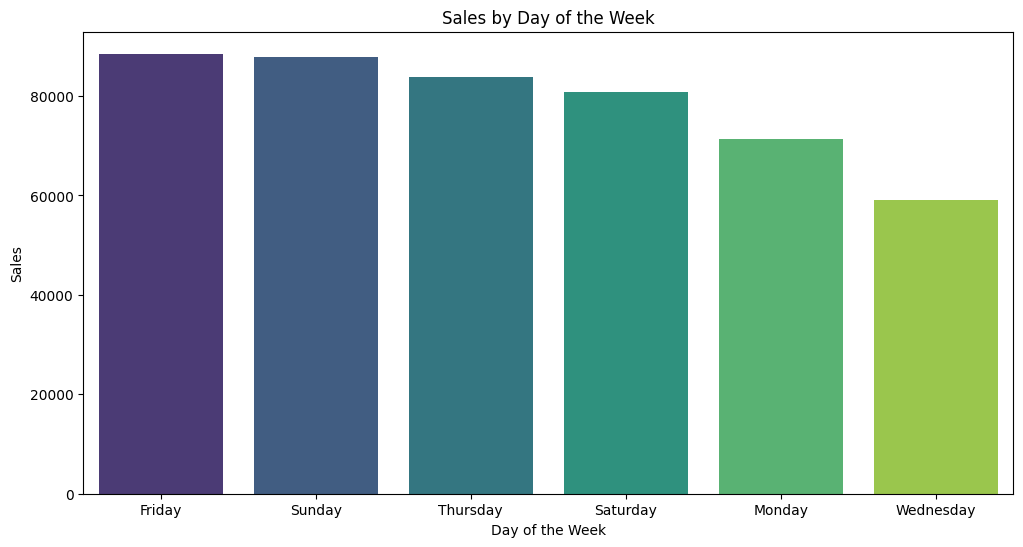

In [28]:
# Create a new 'DayOfWeek' column in the 'transactions' DataFrame with the day of the week of each transaction
# Use the 'dt.day_name()' method to get the day name from the 'Date' column
transactions['DayOfWeek'] = transactions['Date'].dt.day_name()

# Count the number of sales per day of the week with the 'value_counts()' method on the 'DayOfWeek' column
# Store the results in the variable 'sales_by_weekday'
sales_by_weekday = transactions['DayOfWeek'].value_counts()

# Create a figure with the 'figure()' method of the matplotlib.pyplot library with the alias 'plt'
# Define the size of the figure with the 'figsize' parameter and the dimensions (12, 6)
plt.figure(figsize=(12, 6))

# Use the 'barplot()' method of the seaborn library 'sns' to visualize the data as bars
# Define the x-axis with the index values of 'sales_by_weekday'
# Define the y-axis with the values of 'sales_by_weekday'
# Define the color palette with the 'palette' parameter and the value 'viridis'
sns.barplot(x=sales_by_weekday.index, y=sales_by_weekday.values, palette='viridis')

# Define the chart title with the 'title()' method of the matplotlib.pyplot library with the alias 'plt'
# Set the title to 'Sales by Day of the Week'
plt.title('Sales by Day of the Week')

# Define the x-axis label with the 'xlabel()' method of the matplotlib.pyplot library with the alias 'plt'
# Set the x-axis label to 'Day of the Week'
plt.xlabel('Day of the Week')

# Define the y-axis label with the 'ylabel()' method of the matplotlib.pyplot library with the alias 'plt'
# Set the y-axis label to 'Sales'
plt.ylabel('Sales')

# Show the chart with the 'show()' method of the matplotlib.pyplot library with the alias 'plt'
plt.show()